# 01 · EDA interpretado (solo train)

**Fuente de las cifras:** `data/processed/train.parquet` y `reports/results/eda_summary.json`.
No se cargan `val.parquet` ni `test.parquet`: cualquier decisión de esta sección se toma mirando únicamente el pasado (train).

Objetivo: convertir el EDA en decisiones de diseño (filtro, métrica, baseline, split y features), no en una galería de gráficos.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
train = pd.read_parquet(ROOT / "data/processed/train.parquet")
movies = pd.read_parquet(ROOT / "data/processed/movies.parquet")  # metadatos, no contiene ratings
S = json.load(open(ROOT / "reports/results/eda_summary.json", encoding="utf-8"))

print("train:", train.shape, "| columnas:", list(train.columns))
print("rango temporal train:", pd.to_datetime(train.timestamp.min(), unit="s"), "->", pd.to_datetime(train.timestamp.max(), unit="s"))
print("películas (metadatos):", len(movies), "| usuarios en train:", train.userId.nunique())

train: (1610733, 4) | columnas: ['userId', 'movieId', 'rating', 'timestamp']
rango temporal train: 1995-01-09 11:46:49 -> 2019-11-20 21:44:20
películas (metadatos): 10158 | usuarios en train: 15000


## Hallazgo 1 · Los ratings están sesgados hacia arriba

El rating medio de train es **3.570** (desviación **1.056**) y el **51.5%** de las calificaciones es ≥ 4.
El valor más frecuente es **4.0** con **27.1%** de las filas; 5.0 concentra **15.5%**.
Un baseline que siempre predice la media ya obtiene un RMSE de referencia; por eso el RMSE debe compararse contra ese baseline y no contra cero.

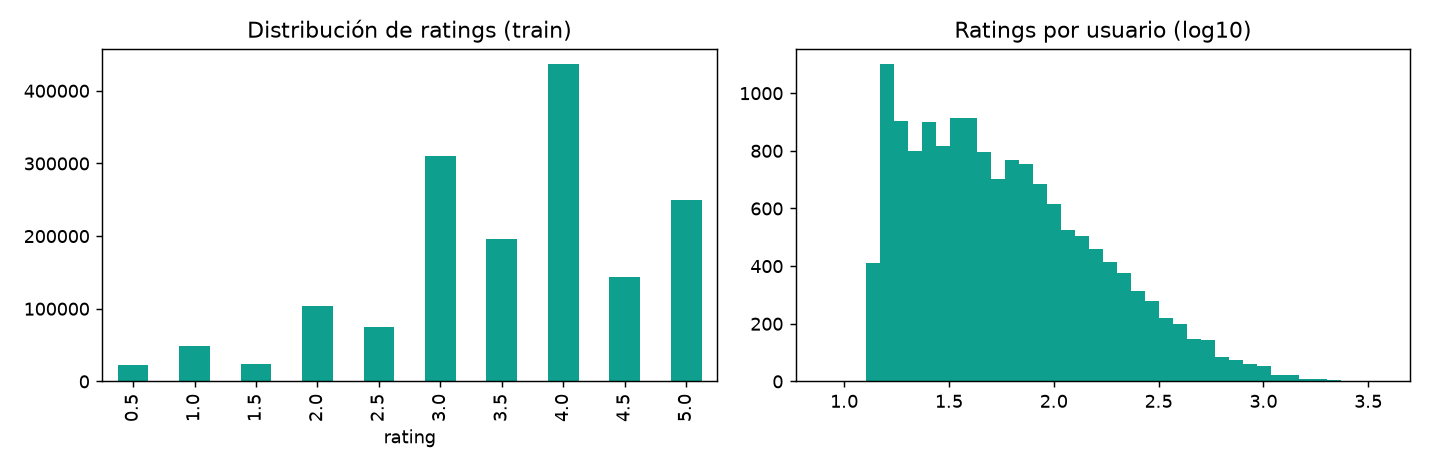

rating medio: 3.57 | desv.: 1.056
% rating >= 4: 51.5 %
participación de cada valor: {'0.5': 0.0139, '1.0': 0.0304, '1.5': 0.015, '2.0': 0.0641, '2.5': 0.0467, '3.0': 0.1928, '3.5': 0.122, '4.0': 0.2709, '4.5': 0.0891, '5.0': 0.155}
rating mínimo/máximo en train: 0.5 5.0


In [2]:
display(Image(filename=ROOT / "reports/figures/eda_ratings_users.png"))
print("rating medio:", round(S["rating_mean"], 4), "| desv.:", round(S["rating_std"], 4))
print("% rating >= 4:", round(S["pct_ratings_ge4"]*100, 2), "%")
print("participación de cada valor:", S["rating_share"])
print("rating mínimo/máximo en train:", train.rating.min(), train.rating.max())

**Por eso decidimos** usar RMSE como métrica principal (penaliza errores grandes), MAE como secundaria interpretable y evaluar además NDCG@10 / Recall@10 con relevancia `rating ≥ 4`, porque la mitad del histórico es “me gustó”. El baseline obligatorio es la media global y, sobre todo, el baseline de sesgos usuario+película.

## Hallazgo 2 · Cola larga de popularidad

Las **10%** películas más calificadas concentran **66.4%** de los ratings y el **1%** concentra **19.7%**.
La mediana de ratings por película es **31** (media **158.8**, máximo **6622**).
La correlación entre popularidad y rating medio es solo **0.169**: popular no significa mejor valorada.

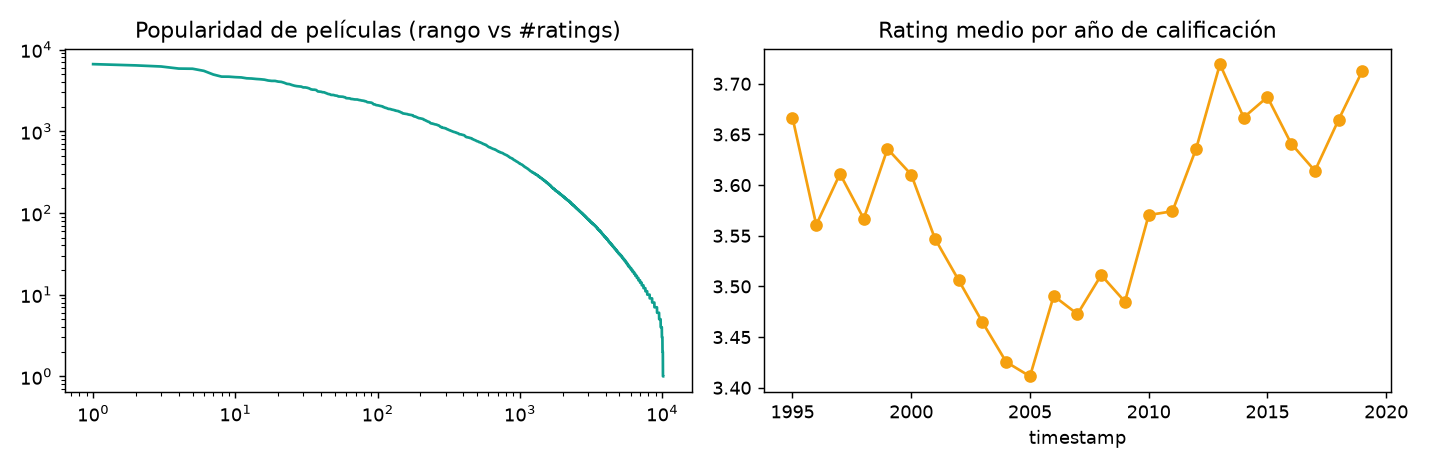

top 10% películas -> 66.4 % de ratings
top 1% películas -> 19.69 % de ratings
ratings por película: {'count': 10146.0, 'mean': 158.8, 'std': 409.8, 'min': 1.0, '25%': 12.0, '50%': 31.0, '75%': 111.0, 'max': 6622.0}
corr(popularidad, rating medio) = 0.1693


In [3]:
display(Image(filename=ROOT / "reports/figures/eda_popularity_drift.png"))
print("top 10% películas ->", round(S["share_ratings_top10pct_movies"]*100, 2), "% de ratings")
print("top 1% películas ->", round(S["share_ratings_top1pct_movies"]*100, 2), "% de ratings")
print("ratings por película:", S["ratings_per_movie"])
print("corr(popularidad, rating medio) =", round(S["corr_movie_popularity_vs_mean_rating"], 4))

**Por eso decidimos** filtrar películas con menos de 50 ratings antes del muestreo y menos de 10 después (documentado en `subset_report.json`), usar amortiguación/shrinkage en medias y vecinos (damping 10, shrink 50) y analizar el error por cuartiles de popularidad. Un modelo que ignore la cola larga se verá bien en promedio y mal en el segmento mayoritario de películas poco calificadas.

## Hallazgo 3 · Actividad muy desigual entre usuarios

La media es **107.4** ratings por usuario, pero la mediana es **50** y el percentil 75 es **113**; el máximo llega a **3702**.
El mínimo observado en train es **8**, por debajo del umbral configurado de 20: el filtro posterior por películas puede dejar usuarios con menos de 20 filas. Es una limitación documentada, no un error silencioso.

In [4]:
uc = train.userId.value_counts()
mc = train.movieId.value_counts()
print("ratings por usuario:", S["ratings_per_user"])
print("usuarios con <20 ratings en train:", int((uc < 20).sum()), "de", len(uc))
q1, q3 = uc.quantile([0.25, 0.75]); iqr = q3 - q1
print("outliers de actividad por usuario (regla 1.5*IQR):", int((uc > q3 + 1.5*iqr).sum()))
print("usuarios que concentran el 50% de los ratings:", int((uc.sort_values(ascending=False).cumsum() <= uc.sum()/2).sum()))

ratings por usuario: {'count': 15000.0, 'mean': 107.4, 'std': 168.4, 'min': 8.0, '25%': 26.0, '50%': 50.0, '75%': 113.0, 'max': 3702.0}
usuarios con <20 ratings en train: 2174 de 15000
outliers de actividad por usuario (regla 1.5*IQR): 1536
usuarios que concentran el 50% de los ratings: 1772


**Por eso decidimos** partir **temporalmente por usuario (70/15/15)**, nunca al azar, y construir las medias/sesos de train con **out-of-fold** (5 folds). También reportamos el error por cuartil de actividad del usuario para no esconder que el rendimiento no es uniforme.

## Hallazgo 4 · Matriz extremadamente dispersa

La densidad de train es del **1.06%** (sparsity **98.94%**): la mayoría de pares usuario-película no tiene ninguna calificación.
Esto hace inviable estimar medias crudas por celda y explica por qué los vecinos/factores necesitan contracción.

In [5]:
print("sparsity train:", round(S["sparsity_train"], 6), "-> densidad:", round((1-S["sparsity_train"])*100, 2), "%")
print("pares posibles (usuarios x películas):", train.userId.nunique() * train.movieId.nunique())
print("pares observados en train:", len(train))

sparsity train: 0.989416 -> densidad: 1.06 %


pares posibles (usuarios x películas): 152190000
pares observados en train: 1610733


**Por eso decidimos** no usar medias crudas como modelo principal: el baseline de sesgos usa damping, Item-KNN usa contracción por co-ocurrencias y Funk SVD aprende factores latentes. La comparación incluye Ridge/HistGB sobre features para contrastar un enfoque tabular.

## Hallazgo 5 · Deriva temporal del rating medio

El rating medio por año de calificación va de **3.411** (en **2005**) a **3.719** (en **2013**); no es estacionario.
Además, las calificaciones de un mismo usuario no llegan en orden aleatorio: el split temporal reproduce el uso real (predecir el futuro con el pasado).

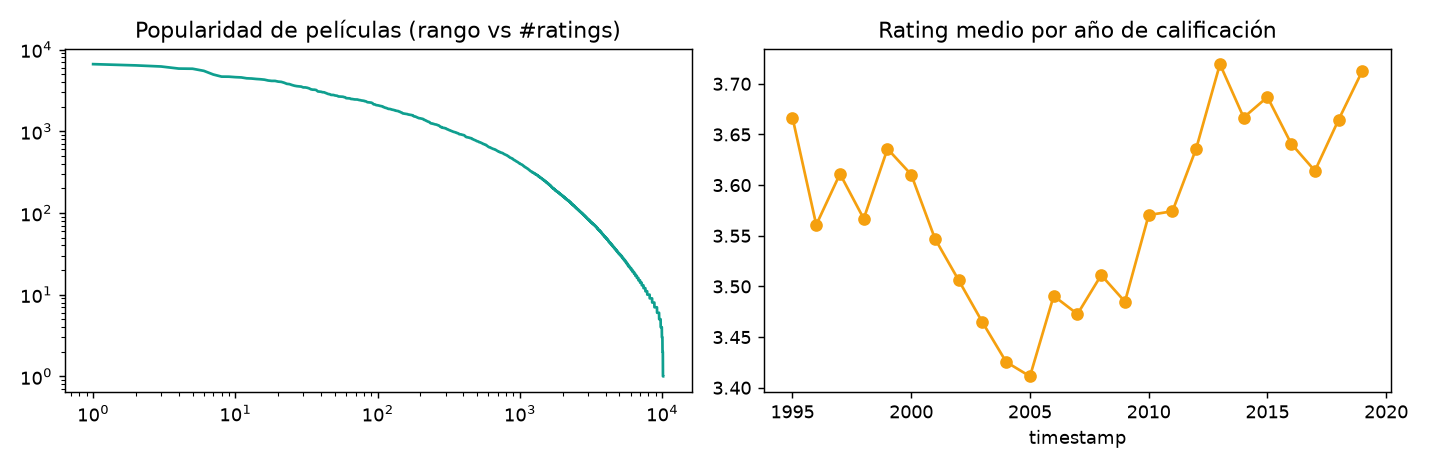

rating medio por año (extracto):
2005    3.411
2012    3.636
2015    3.687
2019    3.713
mínimo: 2005 3.411 | máximo: 2013 3.719


In [6]:
display(Image(filename=ROOT / "reports/figures/eda_popularity_drift.png"))
years = pd.Series(S["mean_rating_by_year"])
print("rating medio por año (extracto):")
sel = [y for y in ["2005","2012","2015","2019"] if y in years.index]
print(years.loc[sel].round(4).to_string())
print("mínimo:", years.idxmin(), round(years.min(),4), "| máximo:", years.idxmax(), round(years.max(),4))

**Por eso decidimos** el split temporal y añadir `year` (año de la película) y `age_at_rating` (año de la calificación menos año de la película) como features tabulares. No usamos variables del futuro ni el año de calificación como target.

## Diagnóstico de calidad

- **Faltantes:** todas las columnas de train tienen 0 valores nulos.
- **Duplicados usuario-película:** 0 en train (se eliminaron en `make_subset`).
- **Rango de rating:** 0.5–5.0, sin valores fuera de rango.
- **Outliers de actividad:** la distribución tiene cola larga; se cuantifica abajo con la regla 1.5·IQR, pero no se eliminan usuarios/películas atípicos porque son señal real de uso.
- **Mínimo de actividad:** el mínimo de train es 8 ratings por usuario (no 20) por el filtro posterior por películas; se reporta como limitación.

In [7]:
quality = pd.DataFrame({
    "nulos": train.isna().sum(),
    "n_unicos": train.nunique(),
})
print(quality)
print("duplicados (userId, movieId):", int(train.duplicated(["userId","movieId"]).sum()))
print("ratings fuera de [0.5, 5]:", int(((train.rating < 0.5) | (train.rating > 5)).sum()))
print("fechas fuera del rango esperado (1970-2020):", int((~pd.to_datetime(train.timestamp, unit="s").dt.year.between(1970, 2020)).sum()))
print("conteo de ratings por usuario (describe):")
print(train.userId.value_counts().describe().round(1).to_string())
print("conteo de ratings por película (describe):")
print(train.movieId.value_counts().describe().round(1).to_string())

           nulos  n_unicos
userId         0     15000
movieId        0     10146
rating         0        10
timestamp      0   1317690


duplicados (userId, movieId): 0
ratings fuera de [0.5, 5]: 0
fechas fuera del rango esperado (1970-2020): 0
conteo de ratings por usuario (describe):
count    15000.0
mean       107.4
std        168.4
min          8.0
25%         26.0
50%         50.0
75%        113.0
max       3702.0
conteo de ratings por película (describe):
count    10146.0
mean       158.8
std        409.8
min          1.0
25%         12.0
50%         31.0
75%        111.0
max       6622.0


## Tabla de leakage: qué podría filtrarse y cómo se evita

| Riesgo de fuga | Cómo se filtraría | Mitigación implementada |
|---|---|---|
| Medias de usuario/película calculadas con todo el dataset | La fila evaluada aporta su propio rating a la media | `src/features.py`: **out-of-fold** en train (5 folds) y estadísticos solo de train en val/test |
| Split aleatorio | El modelo ve ratings futuros del mismo usuario | `src/split.py`: **temporal por usuario** 70/15/15 |
| Elegir modelo/hiperparámetros mirando test | Métricas de test infladas y no reproducibles | `run_supervised` y `run_automl` solo usan **val**; `final_eval` / `error_analysis` leen test una vez |
| Escaladores/PCA ajustados con val/test | Estadísticos del futuro en el preprocesamiento | `StandardScaler` se ajusta dentro del pipeline solo con train; PCA de clustering usa metadatos, no ratings |
| Features de género derivadas del rating de val/test | Afinidad por género con información futura | `genre_affinity` se calcula con train (OOF en train) |
| Ranking con candidatos vistos | Se “acierta” recomendando lo ya visto | `ranking_eval` excluye vistos de train (y de val en test) |
| Tuning de k de clustering con test | Elección contaminada | k se elige por silueta/codo sobre el genoma, sin usar test |

**Nota de auditoría:** la revisión P2 encontró que `src/run_supervised.py`, `src/run_automl.py` y `src/run_clustering.py` cargaban los tres splits con `load_splits` aunque no usaran test para decidir. Se corrigió: ahora esas etapas usan `load_train_val` (ver `src/common.py`) y **solo** `src/final_eval.py` y `src/error_analysis.py` leen `test.parquet`. La decisión metodológica (no mirar test) se mantiene y ahora es comprobable en el código. Ver `reports/decisiones.md`.

## Cierre

Los cinco hallazgos fijan las decisiones que se aplican en el resto del pipeline: métrica RMSE/MAE + ranking, filtros de actividad documentados, split temporal por usuario, features OOF con amortiguación y análisis de errores por segmentos. Las cifras de esta libreta provienen de `train.parquet` y `eda_summary.json`; no se usó `val.parquet` ni `test.parquet`.